# Errors by period: calm, normal and stressed weeks

**Goal:** check whether each model's test errors change with the state of the market, and which model holds up best in each state.

We split the 717 test rows into three periods using f3 (log SPY realised volatility over the past 22 days):
- the two cut-offs are the terciles of f3 on the 2,452 training rows, so no test information decides the groups;
- each test row is then labelled calm, normal or stressed by its own f3;
- we use f3 rather than y (the next 5 days), since f3 is known on the forecast date, whereas y isnt.

**Important:** this notebook only reads the saved test predictions (results/preds_*.csv) and model_table.csv. No model is fitted or re-tuned here.

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Work from the repo root
if os.path.basename(os.getcwd()) == "integration":
    os.chdir("..")

sns.set_theme(style="whitegrid", font_scale=1.1)
os.makedirs("results/figures", exist_ok=True)

model_table = pd.read_csv("data/processed/model_table.csv", parse_dates=["date"])
train = model_table[model_table["split"] == "train"]

print("Training rows:", len(train), "| test rows:", (model_table["split"] == "test").sum())

Training rows: 2452 | test rows: 717


## 2. Load and check the prediction files

Each file must hold the same amount of test dates (717) and the same y as model_table.csv.

We line the files up by date, not by row order.

In [8]:
test = model_table[model_table["split"] == "test"].set_index("date")[["y", "f3"]]
MODELS = {"naive": "Naive", "har": "HAR", "lgbm": "LightGBM", "enet": "Elastic Net"}
NAMES = list(MODELS.values())

errors = test.copy()
for key, name in MODELS.items():
    p = pd.read_csv(f"results/preds_{key}.csv", parse_dates=["date"]).set_index("date")
    
    if len(p) != 717 or not p.index.is_unique:
        raise ValueError(f"{key}: {len(p)} rows or repeated dates")

    if not p.index.sort_values().equals(test.index.sort_values()):
        raise ValueError(f"{key}: dates differ from the test rows")
    
    p = p.reindex(test.index)  # line up by date, not by row position

    if not np.allclose(p["y_true"], test["y"]):
        raise ValueError(f"{key}: y_true differs from model_table")
    
    print(f"{name}: {len(p)} rows, {p.index.min().date()} to {p.index.max().date()}, "
          f"largest y_true gap {(p['y_true'] - test['y']).abs().max():.1e}")
    
    errors[name] = (p["y_true"] - p["y_pred"]).abs()

Naive: 717 rows, 2015-01-02 to 2017-11-03, largest y_true gap 4.4e-16
HAR: 717 rows, 2015-01-02 to 2017-11-03, largest y_true gap 4.4e-16
LightGBM: 717 rows, 2015-01-02 to 2017-11-03, largest y_true gap 0.0e+00
Elastic Net: 717 rows, 2015-01-02 to 2017-11-03, largest y_true gap 4.4e-16


## 3. Cut-offs from the training rows

We make two cut-offs here, using the 1/3 and 2/3 quantiles of f3. That's done because we need to define what a calm, normal, and stressed day means:
- calm: below 1/3 cut-off
- normal: between 1/3 and 2/3
- stressed day: above the 2/3 cut-off.

In [9]:
low, high = train["f3"].quantile([1/3, 2/3])  # training rows only
to_pct = lambda f3: np.exp(f3) * np.sqrt(252 / 22) * 100  # turns log 22-day volatility (f3) into annualised SPY volatility in percent

print(f"Cut-offs on f3: {low:.3f} and {high:.3f} "
      f"(i.e., {to_pct(low):.1f}% and {to_pct(high):.1f}% annualised SPY volatility)")

PERIODS = ["calm", "normal", "stressed"]
def label_period(f3):
    return pd.cut(f3, bins=[-np.inf, low, high, np.inf], labels=PERIODS)

print("Training rows per period:", label_period(train["f3"]).value_counts().reindex(PERIODS).to_dict())
errors["period"] = label_period(errors["f3"])
print("Test rows per period:", errors["period"].value_counts().reindex(PERIODS).to_dict())

Cut-offs on f3: -3.467 and -3.028 (i.e., 10.6% and 16.4% annualised SPY volatility)
Training rows per period: {'calm': 818, 'normal': 816, 'stressed': 818}
Test rows per period: {'calm': 411, 'normal': 173, 'stressed': 133}


## 4. Mean absolute error by period

One row per period and one column per model, with the number of test rows in each period. The "all" row should match results/metrics.csv.

In [10]:
mae = errors.groupby("period", observed=True)[NAMES].mean()

mae.index = mae.index.astype(str)  # plain labels, so we can add an "all" row
mae["test rows"] = errors["period"].value_counts().reindex(PERIODS).to_numpy()
mae.loc["all"] = [*errors[NAMES].mean(), len(errors)]
mae["test rows"] = mae["test rows"].astype(int)
mae.round(3)

,Naive,HAR,LightGBM,Elastic Net,test rows
period,,,,,
calm,0.532,0.440,0.488,0.431,411
normal,0.474,0.407,0.346,0.345,173
stressed,0.353,0.327,0.257,0.245,133
all,0.485,0.411,0.411,0.376,717


## 5. Distribution of the errors by period

The boxes show the middle half of the daily absolute errors, the line inside is the median, and the dots are outlying days.

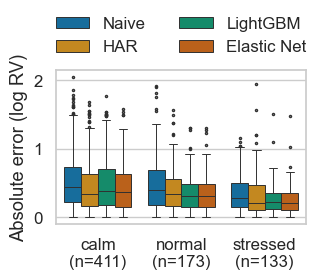

In [11]:
long = errors.melt(id_vars="period", value_vars=NAMES, var_name="model", value_name="abs_error")

fig, ax = plt.subplots(figsize=(3.5, 3.0))  # report width
sns.boxplot(data=long, x="period", y="abs_error", hue="model", palette="colorblind",
            fliersize=1.5, linewidth=0.7, ax=ax)
ax.set_xticks(range(3), [f"{p}\n(n={mae.loc[p, 'test rows']})" for p in PERIODS])
ax.set_xlabel("")
ax.set_ylabel("Absolute error (log RV)")
ax.legend(title=None, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)

plt.tight_layout()
plt.savefig("results/figures/errors_by_period.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Bias by period

The absolute errors in section 4 might hide the direction of the mistakes, so we decided to keep the sign here: error = y_true - y_pred. This way, a negative mean tells the model forecast volatility too high on average, while a positive means too low.

The table below shows that for LightGBM and Elastic Net, calm periods have negative means, while stressed have positive. This possibly comes from the models expecting more volatility than 2015-2017 delivered (maybe because they were trained on data including the 2008 crisis?).

In [12]:
signed = pd.DataFrame(index=test.index)
for key, name in MODELS.items():
    p = pd.read_csv(f"results/preds_{key}.csv", parse_dates=["date"]).set_index("date").reindex(test.index)
    signed[name] = p["y_true"] - p["y_pred"]  # keep the sign: negative = forecast too high

bias = signed.groupby(errors["period"], observed=True)[NAMES].mean()
bias.index = bias.index.astype(str)
bias.loc["all"] = signed[NAMES].mean()
bias.round(3)

,Naive,HAR,LightGBM,Elastic Net
period,,,,
calm,0.073,-0.073,-0.286,-0.193
normal,-0.076,-0.140,-0.020,0.010
stressed,-0.186,-0.156,0.073,0.063
all,-0.011,-0.104,-0.155,-0.097


## 7. Result

- The cut-offs on training f3 are -3.467 and -3.028 (i.e., 10.6% and 16.4% annualised SPY volatility);
- The test rows split into 411 calm, 173 normal and 133 stressed days, against 818, 816 and 818 on the training rows. Thus, the test years were calmer than training;
- Elastic Net has the lowest MAE in all three periods, although in the normal period it is tied with LightGBM (0.345 vs 0.346). In the stressed period, it reaches 0.245 vs HAR's 0.327;
- For every model, the MAE falls from calm to normal to stressed (e.g., Elastic Net: 0.431, 0.345, 0.245);
- The "all" row matches results/metrics.csv (0.485, 0.411, 0.411 and 0.376);
- In the boxplot, the boxes of the four models overlap in every period, so the gaps in MAE are small compared with the day-to-day spread of the errors. The calm period has the most outlying days.
- In the calm period, LightGBM and Elastic Net forecast too high on average (mean signed error -0.286 and -0.193), while HAR is close to zero (-0.073) and the naive forecast is slightly too low (0.073). Thus, a bias towards too-high forecasts explains part of the larger calm errors for the two machine learning models, but not for HAR or the naive forecast, whose calm MAE is still the highest of their three periods;

Obs: the stressed group MAE is the least reliable of the three because it holds only 133 days.